# 特征选择

In [30]:
import math
from sklearn import tree
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import train_test_split

In [31]:
import xgboost as xgb

In [32]:
# 参数设置
columns = x.columns.tolist()  # 保存特征列名
chrom_length = len(columns)  # 染色体长度

# 模拟退火参数
tmp = math.exp(3)  # 初始温度
tmp_min = math.exp(-8)  # 最低温度
alpha = 0.98  # 降温系数
# alpha = 0.9  # 更快降温
k = 0.002  # 影响较差解采纳概率
fitness_history = []  # 保存适应度变化历史


In [33]:
# 是否采纳函数
def is_acceptable(delta_E, tmp):
    if delta_E <= 0:  # ΔE <= 0，直接采纳
        return True
    return random.random() < math.exp(-delta_E / (k * tmp))

# 染色体生成函数
def geneEncoding():
    chrom = [random.randint(0, 1) for _ in range(chrom_length)]
    if sum(chrom) == 0:  # 如果全为0，随机设置一个基因为1
        chrom[random.randint(0, chrom_length - 1)] = 1
    return chrom

# 获取适应度
def getFitness(chrom):
    selected_features = [idx for idx, gene in enumerate(chrom) if gene == 1]
    if not selected_features:  # 如果全0，适应度为0
        return 0
    
    # 使用 XGBoost 回归模型
    clf = xgb.XGBRegressor(objective='reg:squarederror', random_state=42)
    fitness = cross_val_score(clf, train_x.iloc[:, selected_features], train_y, cv=5).mean()
    return fitness

# 从旧解生成新解
def getNewChrom(chrom):
    new_chrom = chrom[:]
    mpoint = random.randint(0, chrom_length - 1)  # 随机选择变异点
    new_chrom[mpoint] = 1 - new_chrom[mpoint]  # 取反
    if sum(new_chrom) == 0:  # 避免全0解
        new_chrom[random.randint(0, chrom_length - 1)] = 1
    return new_chrom

In [ ]:
# 动态调整温度衰减系数
def adaptive_alpha(E_old, E_new, alpha, min_change_threshold=1e-6):
    # 若适应度变化过小，则加速降温
    if abs(E_new - E_old) < min_change_threshold:
        return alpha * 1.2  # 加速降温
    elif E_new > E_old:
        return alpha * 1.1  # 若找到较好解，稍微加速降温
    else:
        return alpha * 0.9  # 若未找到较好解，稍微减慢降温

In [34]:
# 蒙特卡洛模拟：多次重启
def monte_carlo_restart(iterations, initial_temperature, temperature_min, max_no_improve=50):
    best_solution = None
    best_fitness = -float('inf')
    tmp = initial_temperature  # 重新初始化温度

    for _ in range(iterations):
        x_old = geneEncoding()  # 初始随机解
        E_old = getFitness(x_old)  # 计算适应度
        no_improve_count = 0  # 没有改善的计数器

        while tmp > temperature_min:
            # 检查温度是否小于最低温度，若小于则退出
            if tmp <= temperature_min:
                break

            x_new = getNewChrom(x_old)
            E_new = getFitness(x_new)
            delta_E = -(E_new - E_old)
            if is_acceptable(delta_E, tmp):  # 采纳新解
                x_old = x_new
                E_old = E_new
                if E_new > best_fitness:  # 更新最优解
                    best_solution = x_new
                    best_fitness = E_new
                    no_improve_count = 0  # 重置没有改进的计数
                else:
                    no_improve_count += 1

            # 如果连续若干次没有改善，提前停止
            if no_improve_count >= max_no_improve:
                print(f"在迭代中没有明显改进，提前停止")
                break

            # 调整温度和衰减系数
            tmp = adaptive_alpha(E_old, E_new, alpha)  # 调整衰减系数
            tmp *= alpha  # 温度衰减

    return best_solution, best_fitness

In [ ]:
def monte_carlo_mutation(chrom, max_attempts=10, early_stop_threshold=1e-5):
    best_chrom = chrom
    best_fitness = getFitness(chrom)
    
    # 初始适应度
    previous_fitness = best_fitness
    attempts_without_improvement = 0
    
    for _ in range(max_attempts):  # 蒙特卡洛模拟产生多个变异解
        new_chrom = getNewChrom(chrom)
        fitness = getFitness(new_chrom)
        
        if fitness > best_fitness:  # 如果发现更好的解，更新最优解
            best_chrom = new_chrom
            best_fitness = fitness
            attempts_without_improvement = 0  # 重置尝试计数
        else:
            attempts_without_improvement += 1
        
        # 提前停止条件：如果经过若干次没有明显改善，停止计算
        if attempts_without_improvement >= 3:  # 假设3次没有改进即停止
            print("适应度没有明显提升，提前停止变异过程")
            break

        # 提前停止条件：适应度变化过小
        if abs(fitness - previous_fitness) < early_stop_threshold:
            print("适应度变化过小，提前停止变异过程")
            break
        
        previous_fitness = fitness  # 更新前一次适应度
        
    return best_chrom

In [35]:
from collections import deque

def check_early_stop(fitness_history, min_improvement_threshold=1e-5, patience=100):
    """适应度变化停止条件: 如果适应度变化低于阈值并且连续若干次没有明显改进，提前停止"""
    # 如果 fitness_history 的长度小于 patience，直接返回 False
    if len(fitness_history) < patience:
        return False
    
    recent_fitness_changes = []
    for i in range(1, patience + 1):
        # 确保不会越界
        if len(fitness_history) - i - 1 >= 0:
            recent_fitness_changes.append(fitness_history[-i] - fitness_history[-i-1])
    
    # 判断是否所有变化都小于阈值
    if all(abs(change) < min_improvement_threshold for change in recent_fitness_changes):
        return True
    return False

In [ ]:
# 主程序
if __name__ == '__main__':
    # 设置绘图
    plt.xlabel('Temperature')
    plt.ylabel('Fitness')
    plt.xlim((tmp_min, tmp))
    plt.ylim((0.4, 1.0))  # 根据适应度范围调整
    plt.ion()  # 开启实时更新模式

    # 初始化
    x_old = geneEncoding()  # 初始随机解
    E_old = getFitness(x_old)  # 计算初始解的适应度
    best_chrom = x_old
    best_fitness = E_old

    px = []  # 保存温度
    py = []  # 保存适应度

    # 运行蒙特卡洛模拟：多次重启，使用迭代的方式来寻找全局最优解
    best_solution, best_fitness = monte_carlo_restart(
        iterations=100, 
        initial_temperature=tmp, 
        temperature_min=tmp_min
    )

    # 输出最优结果
    selected_features = [columns[idx] for idx, gene in enumerate(best_solution) if gene == 1]
    print(f"最优适应度：{best_fitness}")
    print(f"选择的特征列名：{selected_features}")

    # 调用变异操作
    best_chrom = monte_carlo_mutation(best_solution)  # 使用变异优化当前解
    best_fitness = getFitness(best_chrom)  # 更新变异后的适应度

    # 输出变异后的结果
    selected_features = [columns[idx] for idx, gene in enumerate(best_chrom) if gene == 1]
    print(f"变异后的最优适应度：{best_fitness}")
    print(f"变异后的选择的特征列名：{selected_features}")

    # 在图表中实时绘制温度和适应度变化
    while tmp > tmp_min:
        x_new = getNewChrom(x_old)  # 生成新解
        E_new = getFitness(x_new)  # 计算新解的适应度
        delta_E = -(E_new - E_old)

        if is_acceptable(delta_E, tmp):  # 采纳新解
            x_old = x_new
            E_old = E_new
            if E_new > best_fitness:  # 更新最优解
                best_chrom = x_new
                best_fitness = E_new

        # 动态调整温度衰减系数
        alpha = adaptive_alpha(E_old, E_new, alpha)  # 调整温度衰减系数

        # 降温
        tmp *= alpha

        # 记录历史数据
        px.append(tmp)
        py.append(E_old)
        fitness_history.append(E_old)

        # 检查是否满足提前停止条件
        if check_early_stop(fitness_history):
            print("适应度变化较小，提前停止")
            break

        # 实时绘制适应度变化
        plt.plot(px, py, 'b-')
        plt.pause(0.001)

    plt.ioff()  # 关闭实时更新
    plt.show()  # 显示图形

    # 输出最终的最优结果
    print(f"最终最优适应度：{best_fitness}")
    selected_features = [columns[idx] for idx, gene in enumerate(best_chrom) if gene == 1]
    print(f"最终选择的特征列名：{selected_features}")

In [37]:
fitness_history 

[0.844075710514659,
 0.844075710514659,
 0.8379319888679098,
 0.8402672900156715,
 0.8402672900156715,
 0.8445225540885388,
 0.8226254231325051,
 0.8679513398197869,
 0.8679513398197869,
 0.8679513398197869,
 0.8478728714369165,
 0.8414223781633051,
 0.8504185446687147,
 0.848616801454963,
 0.8420209384867473,
 0.8481919587678872,
 0.8446934050992698,
 0.8446382839945864,
 0.8474880996610764,
 0.8378697049940278,
 0.8463806069397263,
 0.8463806069397263,
 0.8508872176361175,
 0.8360693188385012,
 0.8360693188385012,
 0.8438529702794689,
 0.842663600381022,
 0.8378835113472682,
 0.8280950292225888,
 0.8318275175053245,
 0.8312513345015035,
 0.8403762977495142,
 0.8293299945676829,
 0.831159828682779,
 0.8477390797254957,
 0.8473835816435018,
 0.8473835816435018,
 0.8390069517571979,
 0.8390069517571979,
 0.8390204710468572,
 0.8415997098361874,
 0.8390204710468572,
 0.8356041493942156,
 0.8495615531897155,
 0.8443061638096425,
 0.8495615531897155,
 0.8356041493942156,
 0.855011721579203

In [38]:
from scipy.interpolate import make_interp_spline

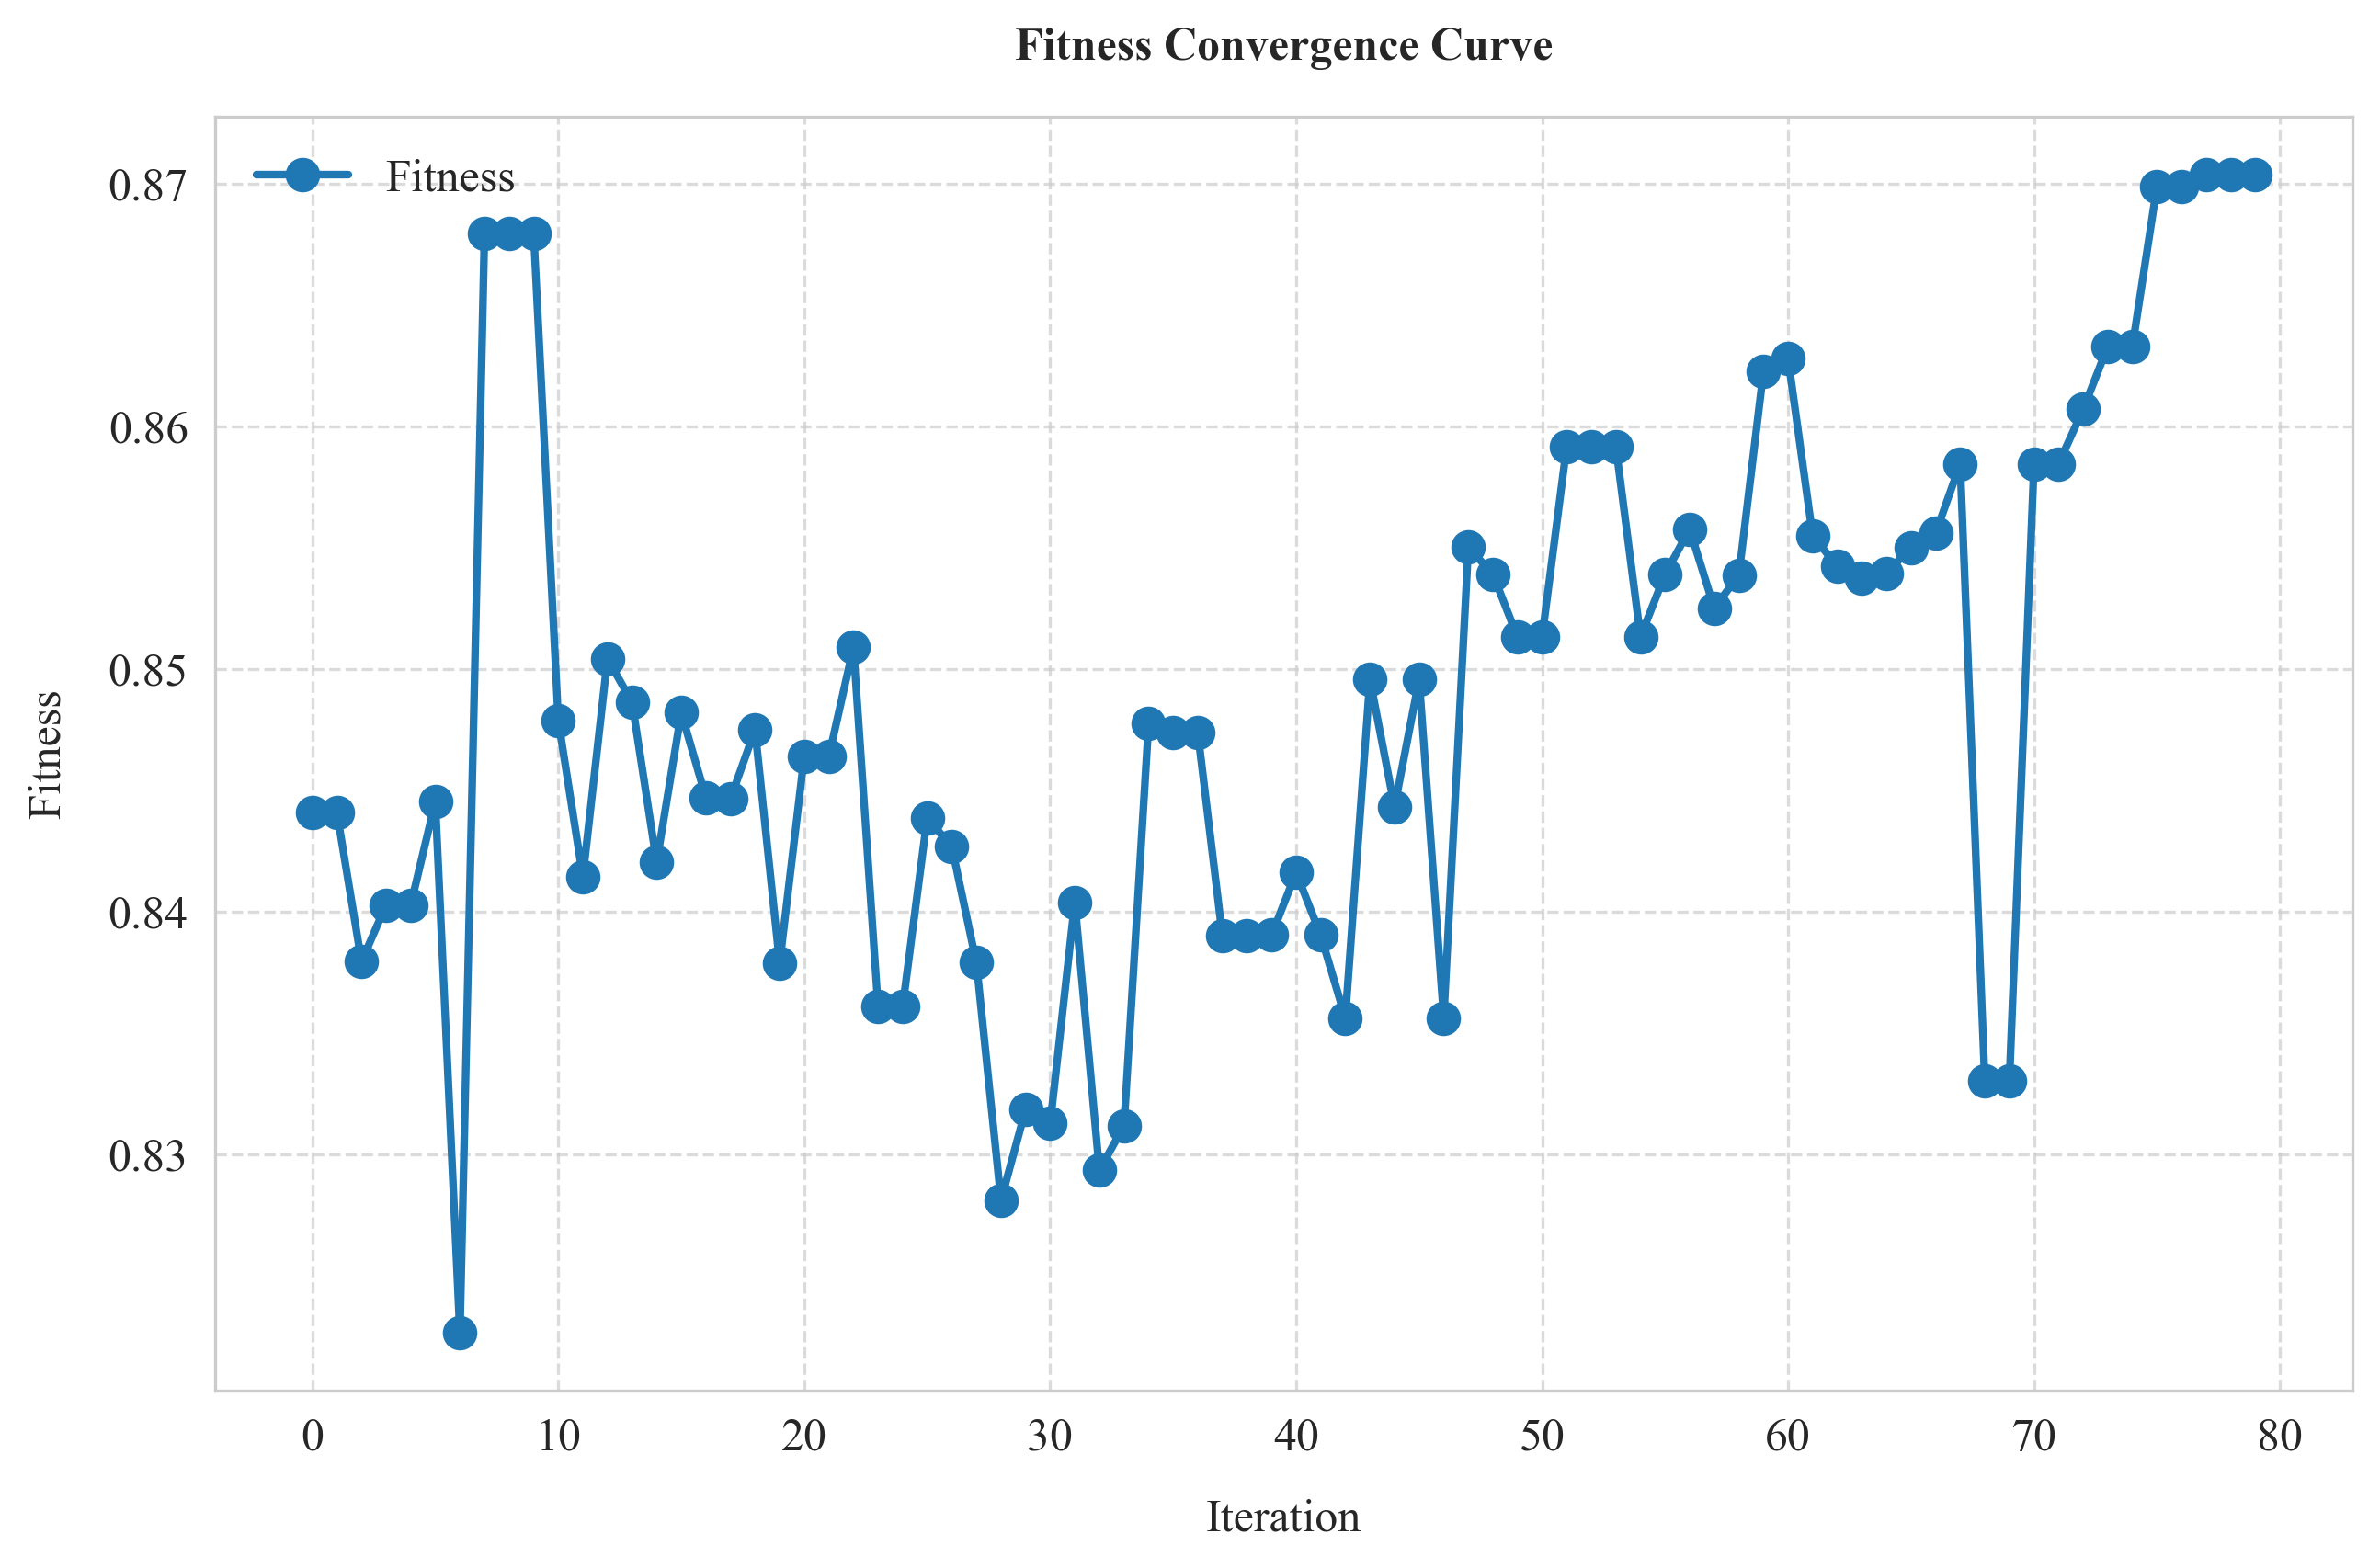

In [39]:
# 配置字体为 Times New Roman
plt.rcParams['font.family'] = 'Times New Roman'

# 绘图
plt.figure(figsize=(10, 6), dpi=300)
plt.plot(range(len(fitness_history)), fitness_history, marker='o', linestyle='-', 
         color='#1f77b4', label='Fitness', linewidth=2, markersize=8)

# 优化标题和标签
plt.title('Fitness Convergence Curve', fontsize=12, fontweight='bold', pad=15)
plt.xlabel('Iteration', fontsize=12, labelpad=10)
plt.ylabel('Fitness', fontsize=12, labelpad=10)

# 优化刻度
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

# 添加图例
plt.legend(fontsize=12, loc='best', frameon=False)

# 添加网格
plt.grid(visible=True, linestyle='--', alpha=0.7)

# 显示图形
plt.show()